# Кластерный анализ методом k-средних (k-means)

## Цель работы

Выявить структуру сходства между отсканированными изображениями цифр на основе семи бинарных признаков с помощью кластерного анализа методом k-средних (k-means). Определить оптимальное количество кластеров и провести содержательную интерпретацию полученных групп.

## Загрузка и предобработка данных

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from scipy.spatial.distance import pdist
from sklearn.feature_selection import mutual_info_classif
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

In [4]:
df = pd.read_csv("digit.dat", sep=";")

In [5]:
# посмотрим на несколько первых записей
df.head()

,A,B,C,D,E,F,G,H,A2,B2,C2,D2,E2,F2,G2,H2
0,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO
1,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO
2,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO
3,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO
4,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE


Видим, что все столбцы признаков повторяются в данных по два раза. Проверим, действительно ли они идентичны.

In [6]:
pairs = [('A','A2'), ('B','B2'), ('C','C2'), ('D','D2'),
         ('E','E2'), ('F','F2'), ('G','G2'), ('H','H2')]

for c1, c2 in pairs:
    a = df[c1].str.strip()
    b = df[c2].str.strip()

    equal = a.equals(b)
    print(f'{c1} vs {c2}: identical = {equal}')

A vs A2: identical = True
B vs B2: identical = True
C vs C2: identical = True
D vs D2: identical = True
E vs E2: identical = True
F vs F2: identical = True
G vs G2: identical = True
H vs H2: identical = True


Теперь удалим эти столбцы, так как они не несут никакой новой информации

In [7]:
df = df.drop(columns=['A2', 'B2', 'C2', 'D2', 'E2', 'F2', 'G2', 'H2'])

Разделим столбцы на признаки и target (переменную в которой лежит сама цифра)

In [8]:
target = 'A'

X = df.drop(columns=[target])
y = df[target]

In [9]:
# интересно, что ONE написано везде с лишним пробелом
# unique() вывел бы пропуски, если бы они имелись - видим, что пропусков нет
for col in X.columns:
  print(f'{col}: {X[col].unique()}')

# лишние пробелы есть и в значениях target
print(f'\nA: {y.unique()}')

B: ['ONE ' 'ZERO']
C: ['ZERO' 'ONE ']
D: ['ONE ' 'ZERO']
E: ['ZERO' 'ONE ']
F: ['ZERO' 'ONE ']
G: ['ONE ' 'ZERO']
H: ['ZERO' 'ONE ']

A: ['seven' 'one  ' 'four ' 'two  ' 'eight' 'five ' 'six  ' 'zero ' 'nine '
 'three']


In [10]:
X = X.replace({'ONE ': 1, 'ZERO': 0}).infer_objects(copy=False)
y = y.str.strip()

data = pd.concat([y, X], axis=1)
data.head()

/tmp/ipykernel_5588/3387429379.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X = X.replace({'ONE ': 1, 'ZERO': 0}).infer_objects(copy=False)


,A,B,C,D,E,F,G,H
0,seven,1,0,1,0,0,1,0
1,one,0,0,1,0,0,1,0
2,four,0,1,1,1,0,1,0
3,two,1,1,1,1,1,0,0
4,eight,0,1,1,1,1,1,1


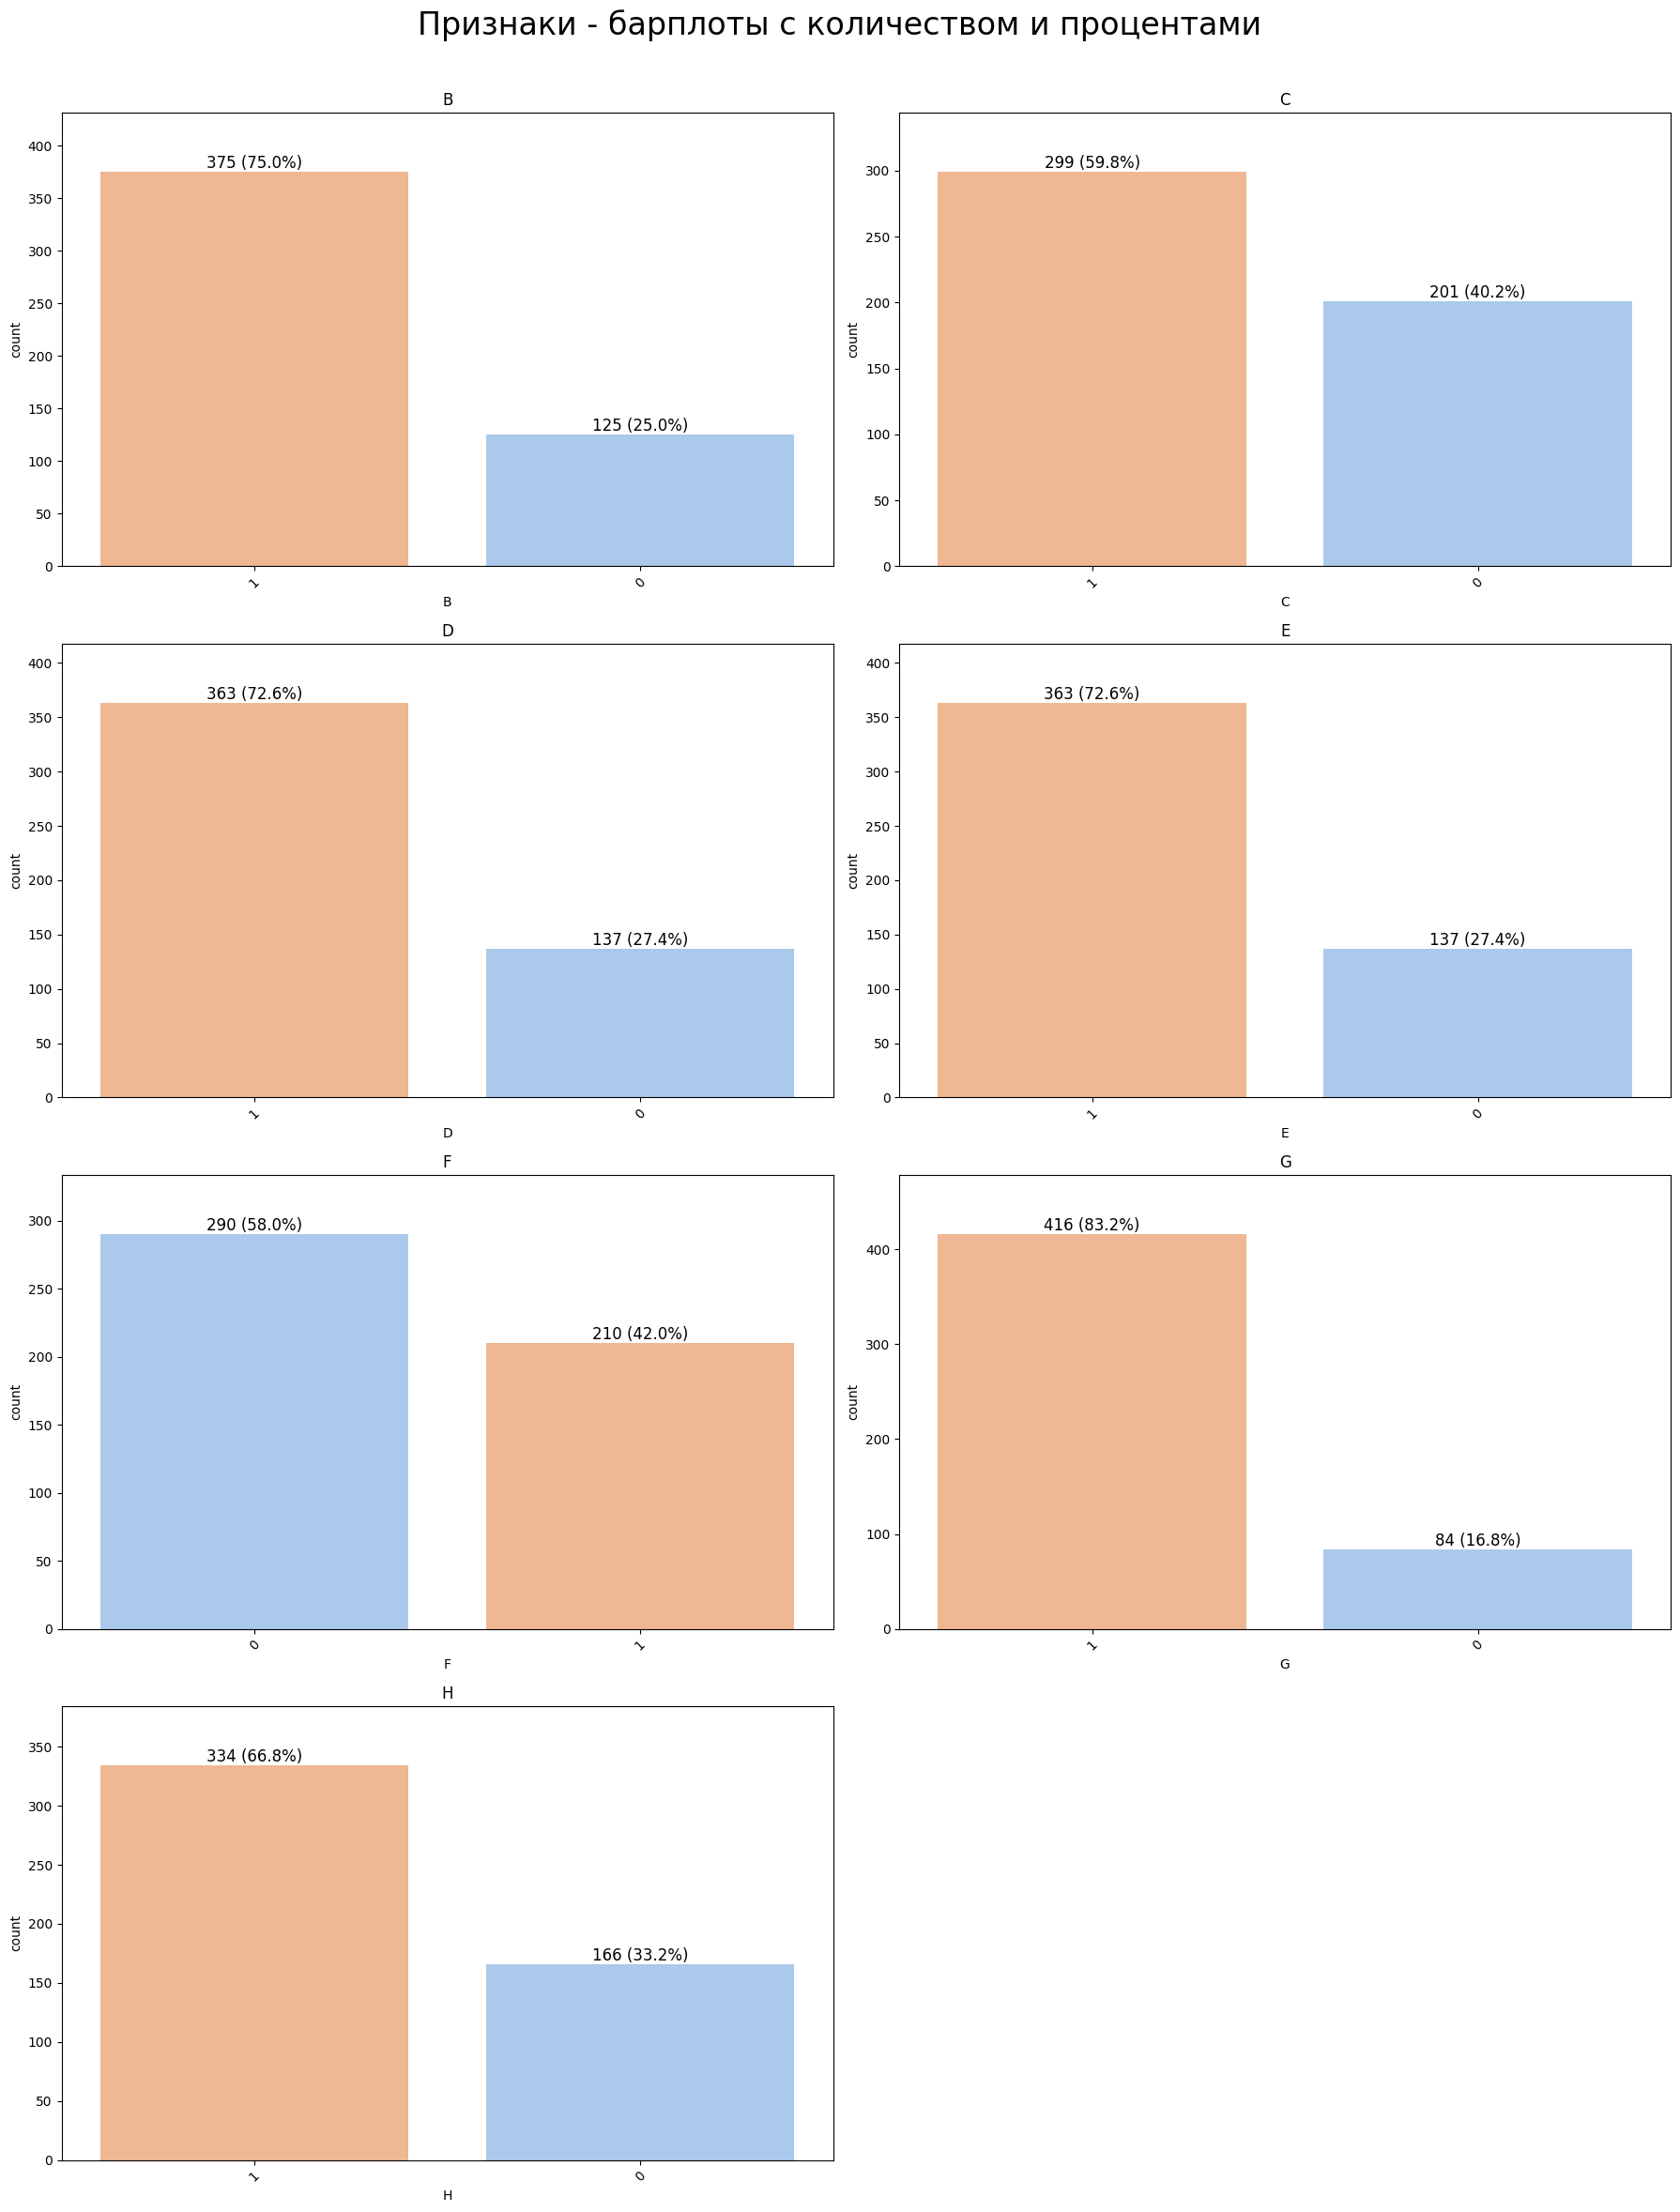

In [11]:
columns = X.columns

n_cat = len(columns)
cols = 2
rows = math.ceil(n_cat / cols)

fig_cat, axes_cat = plt.subplots(rows, cols, figsize=(cols * 9, rows * 6))
axes_cat = axes_cat.flatten()

for i, col in enumerate(columns):
    ax = axes_cat[i]
    order = X[col].value_counts().index
    counts = X[col].value_counts()
    total = len(X)

    sns.countplot(data=X, x=col, hue=col, ax=ax, order=order, palette="pastel", legend=False)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

    for p in ax.patches:
        count = int(p.get_height())
        percent = 100 * count / total
        ax.annotate(
            f"{count} ({percent:.1f}%)",
            (p.get_x() + p.get_width() / 2.0, p.get_height()),
            ha="center",
            va="bottom",
            fontsize=12,
        )
    ax.set_ylim(0, max(counts.values) * 1.15)

# Удаляем лишние оси
for j in range(i + 1, len(axes_cat)):
    fig_cat.delaxes(axes_cat[j])

fig_cat.suptitle("Признаки - барплоты с количеством и процентами", fontsize=24)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

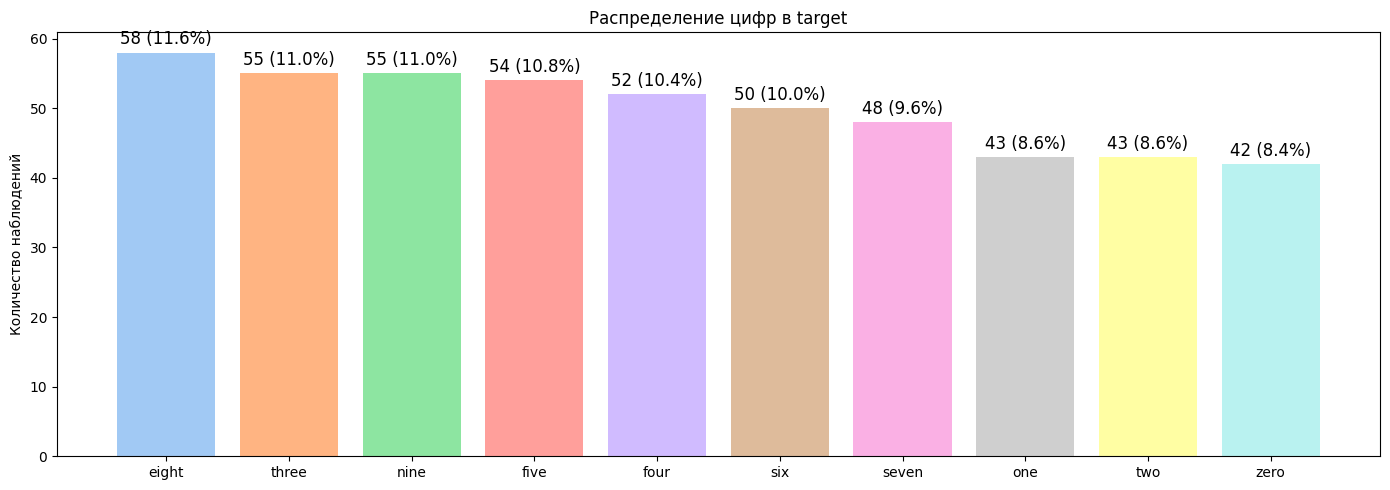

In [12]:
counts = y.value_counts()
pct = y.value_counts(normalize=True) * 100

order = counts.sort_values(ascending=False).index
counts = counts.loc[order]
pct = pct.loc[order]

fig, ax = plt.subplots(figsize=(14, 5))
colors = sns.color_palette("pastel", n_colors=len(counts))

bars = ax.bar(counts.index.astype(str), counts.values, color=colors)

ax.set_title('Распределение цифр в target')
ax.set_ylabel('Количество наблюдений')

ax.bar_label(
    bars,
    labels=[f'{c} ({p:.1f}%)' for c, p in zip(counts.values, pct.values)],
    padding=3, fontsize=12,
)

plt.tight_layout()
plt.show()

In [13]:
def draw_digit_on_ax(
    row_index: int,
    ax: plt.Axes,
    X: pd.DataFrame = X,
    y: pd.DataFrame = y
) -> None:
    """
    Рисует одну цифру на заданной оси по переданному индексу строки

    Параметры:
    row_index : int
        Номер строки в X и y
    ax : matplotlib.axes.Axes
        Ось, на которой выполняется отрисовка
    X : pd.DataFrame
        DataFrame с колонками B–H
    y : pd.DataFrame
        DataFrame с колонкой A
    """
    if row_index >= len(df):
        print(f"Ошибка: индекс {row_index} выходит за пределы DataFrame")
        return

    row = X.iloc[row_index].copy()
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.axis('off')
    ax.set_title(f'Объект {row_index}, цифра {y.iloc[row_index]}', fontsize=14)

    segments = [
        (row['B'], [0.25, 0.75], [1.0, 1.0]),
        (row['C'], [0.25, 0.25], [0.5, 1.0]),
        (row['D'], [0.75, 0.75], [0.5, 1.0]),
        (row['E'], [0.25, 0.75], [0.5, 0.5]),
        (row['F'], [0.25, 0.25], [0.0, 0.5]),
        (row['G'], [0.75, 0.75], [0.0, 0.5]),
        (row['H'], [0.25, 0.75], [0.0, 0.0]),
    ]

    for on, xs, ys in segments:
        ax.plot(xs, ys, color='black' if on == 1 else 'white')

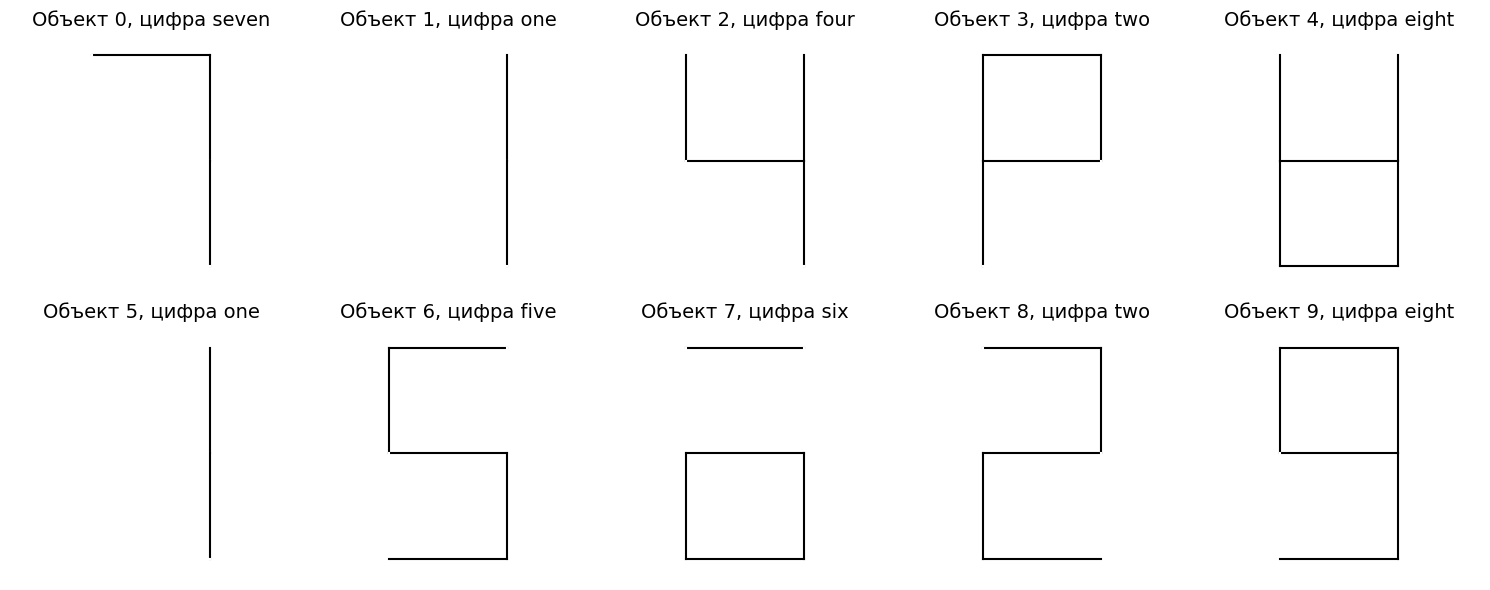

In [14]:
n = 10
cols = 5
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = axes.flatten()

for i in range(n):
    draw_digit_on_ax(i, axes[i])

plt.tight_layout()
plt.show()

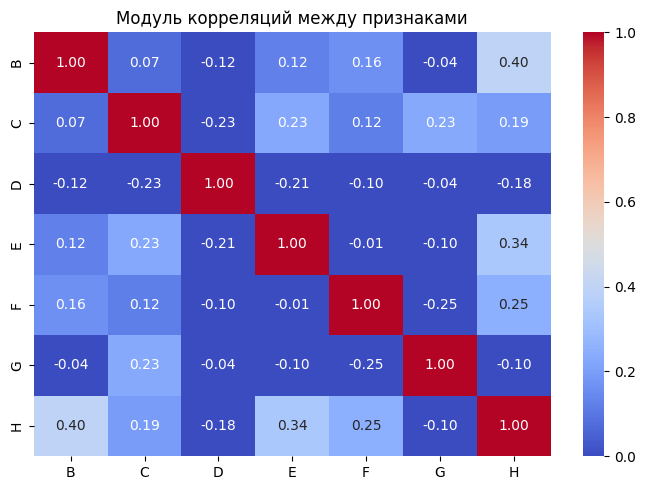

In [15]:
corr_matrix = X.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=0, vmax=1,
    square=False,
    fmt='.2f'
)

plt.title("Модуль корреляций между признаками")
plt.tight_layout()
plt.show()

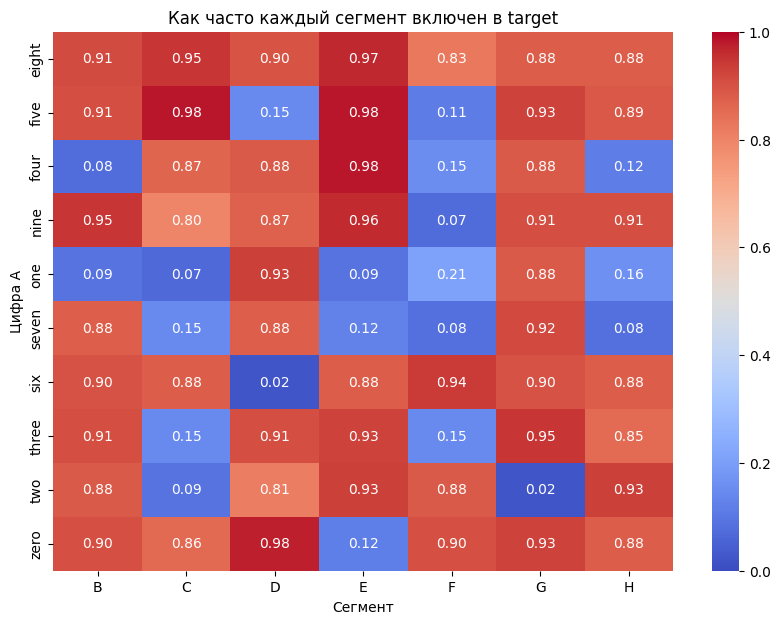

In [16]:
segments = X.columns

profiles = data.groupby('A')[segments].apply(
    lambda x: (x == 1).mean()
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    profiles,
    annot=True,
    cmap='coolwarm',
    vmin=0,
    vmax=1,
    fmt='.2f'
)

plt.xlabel('Сегмент')
plt.ylabel('Цифра A')
plt.title('Как часто каждый сегмент включен в target')
plt.show()

Проведенный разведочный анализ показал, что данные хорошо структурированы и вполне пригодны для иерархической кластеризации, но имеют ряд особенностей, которые необходимо учитывать при выборе метрик.

Распределение признаков (B–H) показывают умеренную или высокую долю единиц. Особенно выделяется сегмент G (нижний правый вертикальный): он равен 1 в 83% наблюдений. Его дисперсия минимальна, поэтому вклад в различение объектов будет небольшим. Остальные сегменты более информативны.

Распределение цифр (переменная A) достаточно сбалансировано: частоты лежат в узком диапазоне от 8,4 % (zero) до 11,6 % (eight). Сильного перекоса нет, поэтому размеры кластеров в дальнейшем не будут сильно искажены частотой отдельных цифр. Это упрощает интерпретацию — если какой-то кластер окажется заметно больше остальных, это скорее отразит реальную схожесть паттернов, а не артефакт несбалансированности.

Графику, показывающий то, как часто сегменты входят в ту или иную цифру из target, доказывает, что в данных есть неправильно отсканированные цифры.

Матрица корреляций (модули) показывает, что сегменты в целом слабо связаны друг с другом. Самые заметные связи — B–H (0,40) и E–H (0,34), остальные значительно ниже. Сильной мультиколлинеарности нет. В связи с этим можно использовать обычные бинарные меры расстояния, не опасаясь сильного искажения из-за зависимых признаков. В то же время наличие даже умеренных корреляций делает чисто евклидово расстояние менее предпочтительным — оно будет частично дублировать информацию.

## Подбор гиперпараметров

Мы посчитали все попарные расстояния Хэмминга между объектами, чтобы понять структуру пространства признаков.

Результаты:
- Минимальное расстояние = 0 значит в данных есть полные дубликаты (объекты с одинаковым набором сегментов).
- Среднее = 0.41, медиана = 0.43 то есть в среднем объекты отличаются примерно в **3 сегментах** из 7.
- 90–95% пар отличаются не больше чем в 5 сегментах.
- Возможные значения расстояния строго дискретны: 0, 1/7, 2/7, 3/7, ..., 1.

DBSCAN работает на основе понятия плотности, которое определяется параметром `eps` (радиус соседства). Поскольку расстояния принимают только несколько фиксированных значений, мы заранее знаем, какие кандидаты `eps` вообще имеют смысл рассматривать. Это сильно сужает пространство поиска гиперпараметров.

In [17]:
hamming_dists = pdist(X, metric='hamming')

print("Статистика попарных расстояний Хэмминга:")
print(f"  min    = {hamming_dists.min():.4f}")
print(f"  mean   = {hamming_dists.mean():.4f}")
print(f"  median = {np.median(hamming_dists):.4f}")
print(f"  90%    = {np.percentile(hamming_dists, 90):.4f}")
print(f"  95%    = {np.percentile(hamming_dists, 95):.4f}")
print(f"  max    = {hamming_dists.max():.4f}")

possible_eps = np.unique(np.round(hamming_dists, 5))
print("\nВозможные значения eps (уникальные расстояния):")
print(possible_eps)

Статистика попарных расстояний Хэмминга:
  min    = 0.0000
  mean   = 0.4096
  median = 0.4286
  90%    = 0.7143
  95%    = 0.7143
  max    = 1.0000

Возможные значения eps (уникальные расстояния):
[0.      0.14286 0.28571 0.42857 0.57143 0.71429 0.85714 1.     ]


Графики показывают расстояние от каждой точки до ее k-го ближайшего соседа (при разных `min_samples`).

Что видно:
- У большой части точек расстояние до k-го соседа равно 0 (это плотные группы дубликатов).
- Затем происходит резкий скачок на уровень 0.143 (1 сегмент различия).
- Потом еще один скачок на уровень 0.286 (2 сегмента).
- Дальше кривая не меняется

Мы ищем место, где кривая резко меняет характер (переход с одного «плато» на другое). Это и есть кандидат на значение `eps`.

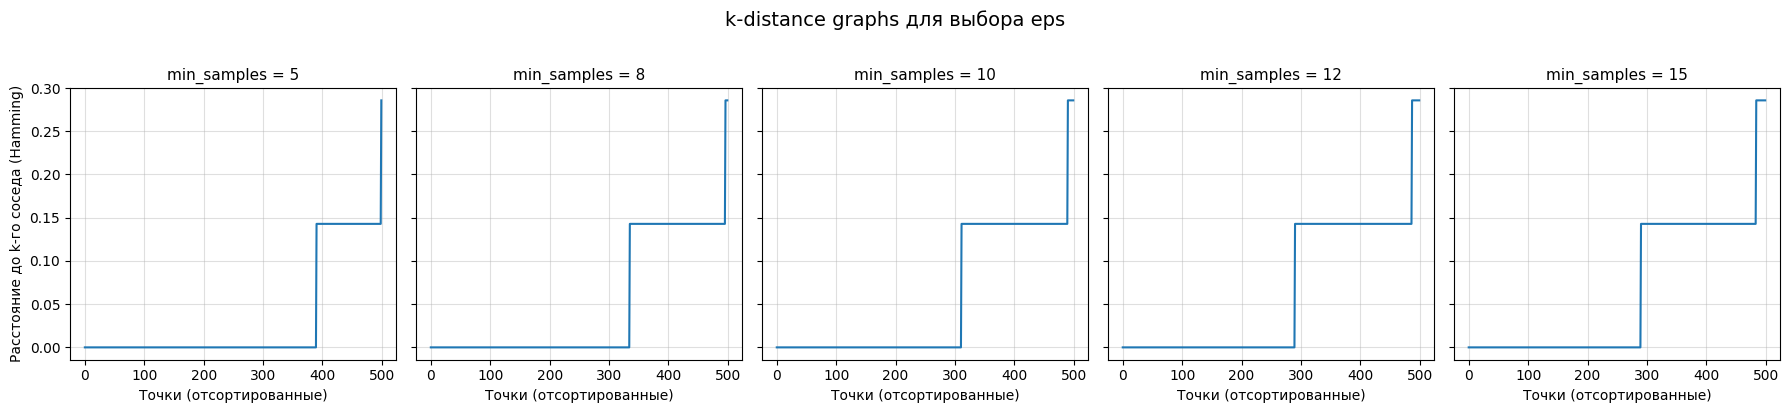

In [20]:
min_samples_list = [5, 8, 10, 12, 15]

fig, axes = plt.subplots(1, len(min_samples_list), figsize=(18, 4), sharey=True)

for ax, min_samples in zip(axes, min_samples_list):
    neighbors = NearestNeighbors(n_neighbors=min_samples, metric='hamming')
    neighbors.fit(X)
    distances, _ = neighbors.kneighbors(X)

    k_distances = np.sort(distances[:, -1])

    ax.plot(k_distances, linewidth=1.5)
    ax.set_title(f'min_samples = {min_samples}', fontsize=11)
    ax.set_xlabel('Точки (отсортированные)')
    ax.grid(True, alpha=0.4)

axes[0].set_ylabel('Расстояние до k-го соседа (Hamming)')
plt.suptitle('k-distance graphs для выбора eps', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

На основании двух предыдущих шагов:

я выбрала eps = 1/7

По сути это единственное значение, при котором DBSCAN ещё находит больше одного кластера.

min_samples = 5–10

При этих значениях шума почти нет, и поведение стабильное

- DBSCAN считает точку «ядровой», если в радиусе `eps` от нее находится минимум `min_samples` соседей
- При `eps = 1/7` алгоритм соединяет только очень похожие объекты (отличающиеся максимум в 1 сегменте) значит получается 2 плотных кластера
- При `eps = 2/7` радиус становится достаточно большим, чтобы почти все группы связались через цепочку соседей значит мы вероятно получим один большой кластер.

In [21]:
eps_candidates = [0.001, 1/7, 2/7, 3/7]
min_samples_candidates = [5, 8, 10, 12]

results = []

for eps in eps_candidates:
    for min_samples in min_samples_candidates:
        db = DBSCAN(eps=eps, min_samples=min_samples, metric='hamming')
        labels = db.fit_predict(X)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)
        noise_pct = n_noise / len(X) * 100

        if n_clusters >= 2 and n_noise < len(X):
            mask = labels != -1
            try:
                sil = silhouette_score(X[mask], labels[mask], metric='hamming')
            except:
                sil = np.nan
        else:
            sil = np.nan

        results.append({
            'eps': round(eps, 4),
            'min_samples': min_samples,
            'n_clusters': n_clusters,
            'n_noise': n_noise,
            'noise_%': round(noise_pct, 1),
            'silhouette': round(sil, 4) if not np.isnan(sil) else None
        })

results_df = pd.DataFrame(results)
print("\nРезультаты перебора параметров:")
print(results_df.to_string(index=False))


Результаты перебора параметров:
   eps  min_samples  n_clusters  n_noise  noise_%  silhouette
0.0010            5          25      110     22.0      1.0000
0.0010            8          15      165     33.0      1.0000
0.0010           10          12      189     37.8      1.0000
0.0010           12          10      210     42.0      1.0000
0.1429            5           2        1      0.2      0.3344
0.1429            8           2        3      0.6      0.3352
0.1429           10           2        6      1.2      0.3371
0.1429           12           2        6      1.2      0.3371
0.2857            5           1        0      0.0         NaN
0.2857            8           1        0      0.0         NaN
0.2857           10           1        0      0.0         NaN
0.2857           12           1        0      0.0         NaN
0.4286            5           1        0      0.0         NaN
0.4286            8           1        0      0.0         NaN
0.4286           10           1      

In [22]:
best_eps = 1/7
best_min_samples = 5

dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples, metric='hamming')
labels_dbscan = dbscan.fit_predict(X)

n_clusters_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = np.sum(labels_dbscan == -1)

print(f"\nИтоговая модель DBSCAN:")
print(f"  eps = {best_eps:.4f}, min_samples = {best_min_samples}")
print(f"  Кластеров: {n_clusters_db}")
print(f"  Шум: {n_noise} ({n_noise/len(X)*100:.1f}%)")


Итоговая модель DBSCAN:
  eps = 0.1429, min_samples = 5
  Кластеров: 2
  Шум: 1 (0.2%)


In [23]:
ct = pd.crosstab(
    labels_dbscan,
    y,
    rownames=['Кластер'],
    colnames=['Цифра'],
    margins=True,
    margins_name='Всего',
)

print(ct)

Цифра    eight  five  four  nine  one  seven  six  three  two  zero  Всего
Кластер                                                                   
-1           0     0     0     0    1      0    0      0    0     0      1
0           53    49     4    52    4     42   45     50   38    38    375
1            5     5    48     3   38      6    5      5    5     4    124
Всего       58    54    52    55   43     48   50     55   43    42    500


## Выводы

Метод DBSCAN с метрикой Хэмминга не позволил получить содержательную кластеризацию изображений цифр.

Анализ попарных расстояний показал, что пространство признаков сильно дискретно (всего 8 возможных значений расстояния), а данные содержат большое количество полных дубликатов. Вследствие этого подбор параметров оказался крайне ограниченным:

- при `eps < 1/7` алгоритм формировал множество мелких кластеров, состоящих только из одинаковых объектов, и объявлял значительную часть точек шумом;
- при `eps = 1/7` выделялось всего **2 кластера** с минимальным количеством шума;
- при `eps ≥ 2/7` все объекты объединялись в **один кластер**.

Даже в лучшем случае (`eps = 0.1429`, `min_samples = 5`) разбиение оказалось слишком грубым и не отражало структуру сходства цифр.

Таким образом, DBSCAN оказался плохо применим к данным из-за высокой дискретности признакового пространства и наличия большого числа одинаковых наблюдений. Намного более информативные и интерпретируемые результаты были получены с помощью иерархической кластеризации и K-Means.